# TP Jour 4 – UC-08 : analyse des données et visualisation

**Retail Intelligence Platform** – IPSSI, Mastère Développement, Data & IA – TP du 19/11/2026 – Nassim Boufalous

**Objectif.** Exploiter les jeux **Silver** et **Gold** produits au Jour 3 (pipeline PySpark, HDFS `/retail-lake`) pour
calculer les KPI du dictionnaire du Jour 1, produire des statistiques descriptives, répondre à des questions métier
du Jour 1 et les illustrer par des graphiques lisibles.

**Démarche (TP §1.1.1).** Spark lit les données complètes et fait **tous les calculs et agrégations** ; seul le petit
tableau de résultat est transféré dans Pandas (`toPandas()`), puis Matplotlib dessine le graphique. Aucune table
détaillée (1,35 million de lignes) n'est transférée dans Pandas.

| Question métier (Jour 1) | Analyse du notebook | Graphique |
|---|---|---|
| Q1 – Comment évolue le CA par année / mois ? Q2 – Répartition magasin / web ? | Analyse 1 | `evolution_ventes_mensuelles.png` |
| Q6 – Quels magasins réalisent le plus de CA et de tickets, lesquels sont en retrait ? | Analyse 2 | `ventes_par_magasin.png` |
| Q3 – Quelles catégories génèrent le plus de CA ? | Analyse 3 | `ventes_par_categorie.png` |
| Q8 – Quel taux de retour par catégorie ? | Analyse 4 | `taux_retour_categorie.png` |
| Q7 – Panier moyen : comment se répartissent les montants des transactions ? | Statistiques | `distribution_montant_transaction.png` |

> Les données TPCx-BB sont **synthétiques** : les résultats illustrent une démarche analytique, ils ne décrivent pas
> une entreprise réelle. Montants en **unité monétaire du kit** (devise non documentée), hors taxe.

## 1. Paramètres, bibliothèques et environnement

Tous les chemins sont définis ici. Les variables `JAVA_HOME` et `HADOOP_CONF_DIR` sont celles validées au Jour 3
(Java 17 pour Spark 4 ; configuration HDFS du Jour 2, sinon Spark écrit avec une réplication 3 sur un seul DataNode).

In [1]:
import os
import sys
import platform
from datetime import datetime
from pathlib import Path

# --- Environnement validé au Jour 3 (WSL Ubuntu 24.04) : à définir AVANT la création de la session Spark
os.environ.setdefault("JAVA_HOME", "/usr/lib/jvm/java-17-openjdk-amd64")
os.environ.setdefault("HADOOP_CONF_DIR", "/opt/hadoop/etc/hadoop")
os.environ.setdefault("PYSPARK_PYTHON", sys.executable)

# --- Paramètres
LAKE = os.environ.get("TP4_LAKE", "hdfs://localhost:9000/retail-lake")   # Data Lake du Jour 2 / Jour 3
SILVER, GOLD = f"{LAKE}/silver", f"{LAKE}/gold"
J4 = Path.cwd().resolve().parents[1]                  # le notebook est dans Jour4/analytics/notebooks/
assert J4.name == "Jour4", f"Lancer le notebook depuis Jour4/analytics/notebooks (cwd = {Path.cwd()})"
OUT = J4 / "analytics" / "outputs"                    # tableaux CSV
VIZ = J4 / "analytics" / "visualizations"             # graphiques PNG
J3_PREUVES = J4.parent / "Jour3" / "UC06_preuves"     # contrôles qualité et KPI du Jour 3
for d in (OUT, VIZ):
    d.mkdir(parents=True, exist_ok=True)

SOURCE = "Source : Gold/Silver du Data Lake HDFS /retail-lake (pipeline Jour 3) – kit TPCx-BB synthétique, lots initial + refresh"
print("Data Lake :", LAKE)
print("Exports   :", OUT.relative_to(J4.parent), "|", VIZ.relative_to(J4.parent))

Data Lake : hdfs://localhost:9000/retail-lake
Exports   : Jour4/analytics/outputs | Jour4/analytics/visualizations


In [2]:
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pyspark
from pyspark.sql import SparkSession, functions as F, Window

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)


def exporter(pdf, nom):
    # Exporte un petit tableau Pandas en CSV (séparateur ; et BOM pour l'ouverture dans Excel)
    chemin = OUT / f"{nom}.csv"
    pdf.to_csv(chemin, index=False, sep=";", encoding="utf-8-sig")
    print(f"-> {chemin.relative_to(J4.parent)} ({len(pdf)} lignes)")


# Style commun des graphiques : fond blanc, grille légère, couleurs fixes par canal (toujours les mêmes)
ENCRE, ENCRE2, GRILLE = "#0b0b0b", "#52514e", "#e1e0d9"
COULEUR_CANAL = {"magasin": "#2a78d6", "web": "#eb6834"}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
    "axes.edgecolor": GRILLE, "axes.labelcolor": ENCRE2, "xtick.color": ENCRE2, "ytick.color": ENCRE2,
    "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "axes.axisbelow": True, "text.color": ENCRE,
})


def finaliser(fig, nom, note=""):
    # Ajoute la source et la note de périmètre sous le graphique, puis l'enregistre en PNG
    fig.text(0.01, -0.02, SOURCE + (f"\n{note}" if note else ""), fontsize=7.5, color=ENCRE2, ha="left", va="top")
    chemin = VIZ / f"{nom}.png"
    fig.savefig(chemin, bbox_inches="tight", facecolor="white")
    print(f"-> {chemin.relative_to(J4.parent)}")
    plt.show()


env = pd.DataFrame([
    ("Date d'exécution", datetime.now().strftime("%Y-%m-%d %H:%M")),
    ("Système", f"{platform.system()} {platform.release()}"),
    ("Python", platform.python_version()),
    ("Exécutable Python (noyau)", sys.executable),
    ("PySpark", pyspark.__version__),
    ("Pandas", pd.__version__),
    ("Matplotlib", matplotlib.__version__),
    ("JAVA_HOME", os.environ["JAVA_HOME"]),
    ("HADOOP_CONF_DIR", os.environ["HADOOP_CONF_DIR"]),
], columns=["element", "valeur"])
env

,element,valeur
0,Date d'exécution,2026-11-19 10:45
1,Système,Linux 6.6.87.2-microsoft-standard-WSL2
2,Python,3.12.3
3,Exécutable Python (noyau),/home/etudiant/venv-tp3/bin/python
4,PySpark,4.3.0
5,Pandas,2.3.3
6,Matplotlib,3.11.2
7,JAVA_HOME,/usr/lib/jvm/java-17-openjdk-amd64
8,HADOOP_CONF_DIR,/opt/hadoop/etc/hadoop


## 2. Session Spark

`local[*]` : Spark s'exécute sur la machine locale avec tous les processeurs (même réglage qu'au Jour 3).

In [3]:
spark = (
    SparkSession.builder
    .appName("TP4-Retail-Intelligence")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "16")      # petits volumes : 16 partitions suffisent
    .config("spark.sql.session.timeZone", "Europe/Paris")
    .config("spark.driver.memory", "6g")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
env = pd.concat([env, pd.DataFrame([("Spark", spark.version), ("Java (JVM de Spark)",
      spark.sparkContext._jvm.java.lang.System.getProperty("java.version")),
      ("Mode d'exécution", spark.sparkContext.master),
      ("Hadoop (client de Spark)", spark.sparkContext._jvm.org.apache.hadoop.util.VersionInfo.getVersion())],
      columns=["element", "valeur"])], ignore_index=True)
exporter(env, "environnement")
print("Version Spark :", spark.version)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
26/11/19 10:45:51 WARN Utils: Your hostname, retail-lake-vm, resolves to a loopback address: 127.0.1.1; using 10.255.255.254 instead (on interface lo)
26/11/19 10:45:51 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/19 10:45:52 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


-> Jour4/analytics/outputs/environnement.csv (13 lignes)
Version Spark : 4.3.0


## 3. Chargement et inventaire des jeux de données (livrable J4-01)

On retient **un jeu Gold principal** (`gold/fait_ventes`, une ligne par ligne de vente des deux canaux) et des jeux
**Silver** (`silver/store_sales` pour le contrôle croisé, `silver/store` pour les attributs des magasins), plus trois
agrégats Gold du Jour 3 utilisés pour le taux de retour et pour vérifier nos recalculs.

In [4]:
JEUX = {
    # nom : (zone, chemin, granularité, usage dans le TP4)
    "gold/fait_ventes": ("Gold", f"{GOLD}/fait_ventes",
        "1 ligne de vente (canal, ticket ou commande, article) ; clé technique ligne_id",
        "KPI K01-K04, K06, K07, K12 ; statistiques ; analyses 1, 2, 3"),
    "gold/ventes_mensuelles_canal": ("Gold", f"{GOLD}/ventes_mensuelles_canal",
        "1 ligne par année x mois x canal", "contrôle croisé de l'analyse 1"),
    "gold/ventes_magasin_annee": ("Gold", f"{GOLD}/ventes_magasin_annee",
        "1 ligne par année x magasin", "contrôle croisé de l'analyse 2"),
    "gold/retours_categorie": ("Gold", f"{GOLD}/retours_categorie",
        "1 ligne par année de vente x canal x catégorie", "KPI K09 (taux de retour) ; analyse 4"),
    "silver/store_sales": ("Silver", f"{SILVER}/store_sales",
        "1 ligne de ticket de caisse (ticket, article) ; clé technique ligne_id",
        "contrôle Silver = Gold ; cohérence des tickets"),
    "silver/store": ("Silver", f"{SILVER}/store", "1 ligne par magasin (12 magasins)",
        "nom, ville, surface et effectif des magasins (analyse 2)"),
}
df = {nom: spark.read.parquet(chemin) for nom, (_, chemin, _, _) in JEUX.items()}

inventaire = pd.DataFrame([{
    "jeu": nom, "zone": zone, "format": "Parquet (Snappy)", "chemin": chemin.replace(LAKE, "/retail-lake"),
    "provenance": "pipeline UC-06 du Jour 3 (Jour3/transformations/03_silver.py, 04_gold.py) sur le kit TPCx-BB",
    "lignes": df[nom].count(), "colonnes": len(df[nom].columns), "granularite": grain, "usage": usage,
} for nom, (zone, chemin, grain, usage) in JEUX.items()])
exporter(inventaire, "inventaire_jeux")
inventaire[["jeu", "zone", "lignes", "colonnes", "granularite", "usage"]]

-> Jour4/analytics/outputs/inventaire_jeux.csv (6 lignes)


,jeu,zone,lignes,colonnes,granularite,usage
0,gold/fait_ventes,Gold,1349142,22,"1 ligne de vente (canal, ticket ou commande, a...","KPI K01-K04, K06, K07, K12 ; statistiques ; an..."
1,gold/ventes_mensuelles_canal,Gold,120,12,1 ligne par année x mois x canal,contrôle croisé de l'analyse 1
2,gold/ventes_magasin_annee,Gold,60,14,1 ligne par année x magasin,contrôle croisé de l'analyse 2
3,gold/retours_categorie,Gold,90,12,1 ligne par année de vente x canal x catégorie,KPI K09 (taux de retour) ; analyse 4
4,silver/store_sales,Silver,674211,33,"1 ligne de ticket de caisse (ticket, article) ...",contrôle Silver = Gold ; cohérence des tickets
5,silver/store,Silver,12,33,1 ligne par magasin (12 magasins),"nom, ville, surface et effectif des magasins (..."


In [5]:
fv = df["gold/fait_ventes"]
fv.printSchema()
fv.select("canal", "date_vente", "document_id", "item_sk", "store_sk", "quantite", "prix_unitaire",
          "montant_ht", "categorie", "lot_source", "annee").show(5, truncate=False)

root
 |-- canal: string (nullable = true)
 |-- ligne_id: string (nullable = true)
 |-- date_vente: date (nullable = true)
 |-- mois: integer (nullable = true)
 |-- document_id: long (nullable = true)
 |-- item_sk: long (nullable = true)
 |-- store_sk: long (nullable = true)
 |-- client_sk: long (nullable = true)
 |-- promo_sk: long (nullable = true)
 |-- quantite: integer (nullable = true)
 |-- prix_unitaire: decimal(7,2) (nullable = true)
 |-- montant_ht: decimal(7,2) (nullable = true)
 |-- remise: decimal(7,2) (nullable = true)
 |-- montant_net_paye: decimal(7,2) (nullable = true)
 |-- cout_achat: decimal(7,2) (nullable = true)
 |-- marge: decimal(7,2) (nullable = true)
 |-- marge_negative: boolean (nullable = true)
 |-- lot_source: string (nullable = true)
 |-- categorie: string (nullable = true)
 |-- categorie_id: integer (nullable = true)
 |-- gold_calcule_le: timestamp (nullable = true)
 |-- annee: integer (nullable = true)



+-----+----------+-----------+-------+--------+--------+-------------+----------+-----------+----------+-----+
|canal|date_vente|document_id|item_sk|store_sk|quantite|prix_unitaire|montant_ht|categorie  |lot_source|annee|
+-----+----------+-----------+-------+--------+--------+-------------+----------+-----------+----------+-----+
|web  |2004-01-01|53971      |9233   |NULL    |8       |12.49        |99.92     |Movies & TV|initial   |2004 |
|web  |2004-01-01|53971      |16497  |NULL    |38      |35.75        |1358.50   |Music      |initial   |2004 |
|web  |2004-01-01|53971      |929    |NULL    |46      |14.26        |655.96    |Music      |initial   |2004 |
|web  |2004-01-01|53971      |10003  |NULL    |40      |54.27        |2170.80   |Electronics|initial   |2004 |
|web  |2004-01-01|53971      |1328   |NULL    |9       |8.51         |76.59     |Books      |initial   |2004 |
+-----+----------+-----------+-------+--------+--------+-------------+----------+-----------+----------+-----+
o

In [6]:
# Schémas observés des jeux utilisés (exportés pour l'inventaire)
schemas = pd.DataFrame([(nom, c.name, c.dataType.simpleString(), c.nullable)
                        for nom in JEUX for c in df[nom].schema.fields],
                       columns=["jeu", "colonne", "type", "nullable"])
exporter(schemas, "schemas_jeux")
schemas.groupby("jeu").size().rename("nb_colonnes").to_frame()

-> Jour4/analytics/outputs/schemas_jeux.csv (126 lignes)


,nb_colonnes
jeu,
gold/fait_ventes,22
gold/retours_categorie,12
gold/ventes_magasin_annee,14
gold/ventes_mensuelles_canal,12
silver/store,33
silver/store_sales,33


## 4. Vérifications préalables (TP §6.3) : qualité, granularité, cohérence

Avant tout KPI, on vérifie sur les données **complètes** : valeurs manquantes des colonnes utilisées, unicité de la
clé, période couverte, granularité (une ligne n'est **pas** une transaction), cohérence d'un ticket (un seul magasin,
une seule date) et égalité Silver = Gold. Les contrôles qualité du Jour 3 sont rappelés juste après.

In [7]:
COLS = ["canal", "date_vente", "document_id", "item_sk", "quantite", "prix_unitaire", "montant_ht", "categorie"]
nulls = fv.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in COLS]
                  + [F.sum((F.col("store_sk").isNull() & (F.col("canal") == "magasin")).cast("int"))
                     .alias("store_sk (canal magasin)")]).toPandas().T.reset_index()
nulls.columns = ["colonne", "valeurs_manquantes"]

controles = []
def controle(nom, resultat, attendu, ok):
    controles.append({"controle": nom, "resultat": resultat, "attendu": attendu, "statut": "OK" if ok else "ÉCART"})

n_lignes = fv.count()
n_ligne_id = fv.select("ligne_id").distinct().count()
controle("Unicité de la clé technique ligne_id (gold/fait_ventes)", f"{n_ligne_id} distinctes / {n_lignes} lignes",
         "égalité", n_ligne_id == n_lignes)
controle("Valeurs manquantes sur les colonnes utilisées par les KPI", int(nulls.valeurs_manquantes.sum()), 0,
         int(nulls.valeurs_manquantes.sum()) == 0)

periode = fv.groupBy("canal").agg(F.min("date_vente").alias("debut"), F.max("date_vente").alias("fin"),
                                  F.countDistinct("date_vente").alias("jours_avec_ventes"),
                                  F.countDistinct("annee", "mois").alias("mois_couverts")).toPandas()
for r in periode.itertuples():
    controle(f"Période couverte, canal {r.canal}", f"{r.debut} -> {r.fin} ; {r.mois_couverts} mois ; "
             f"{r.jours_avec_ventes} jours avec ventes", "60 mois complets (2001-2005)", r.mois_couverts == 60)

# Granularité : une ligne = un article d'un ticket ; nombre de lignes par transaction
grain = (fv.groupBy("canal").agg(F.count("*").alias("lignes"), F.countDistinct("document_id").alias("transactions"))
         .withColumn("lignes_par_transaction", F.round(F.col("lignes") / F.col("transactions"), 2)).toPandas())
for r in grain.itertuples():
    controle(f"Granularité, canal {r.canal} : lignes vs transactions distinctes",
             f"{r.lignes} lignes, {r.transactions} transactions ({r.lignes_par_transaction} lignes / transaction)",
             "lignes > transactions (ne pas confondre)", r.lignes > r.transactions)

# Un ticket magasin = un seul magasin et une seule date (sinon le panier moyen par magasin n'aurait pas de sens)
tk = (fv.filter("canal = 'magasin'").groupBy("document_id")
      .agg(F.countDistinct("store_sk").alias("m"), F.countDistinct("date_vente").alias("d")))
n_incoh = tk.filter("m > 1 or d > 1").count()
controle("Ticket magasin rattaché à un seul magasin et une seule date", f"{n_incoh} ticket(s) incohérent(s)", 0,
         n_incoh == 0)

# Silver = Gold (canal magasin) : même nombre de lignes et même CA au centime
ss = df["silver/store_sales"].agg(F.count("*").alias("n"), F.sum("ss_ext_sales_price").alias("ca")).first()
gm = fv.filter("canal = 'magasin'").agg(F.count("*").alias("n"), F.sum("montant_ht").alias("ca")).first()
controle("Silver store_sales = Gold fait_ventes (canal magasin) : lignes et CA",
         f"lignes {ss.n} / {gm.n} ; CA {ss.ca} / {gm.ca}", "égalité", ss.n == gm.n and ss.ca == gm.ca)

controles = pd.DataFrame(controles)
exporter(nulls, "valeurs_manquantes")
exporter(controles, "controles_prealables")
display(nulls)
controles

-> Jour4/analytics/outputs/valeurs_manquantes.csv (9 lignes)
-> Jour4/analytics/outputs/controles_prealables.csv (8 lignes)


,colonne,valeurs_manquantes
0,canal,0
1,date_vente,0
2,document_id,0
3,item_sk,0
4,quantite,0
5,prix_unitaire,0
6,montant_ht,0
7,categorie,0
8,store_sk (canal magasin),0


,controle,resultat,attendu,statut
0,Unicité de la clé technique ligne_id (gold/fai...,1349142 distinctes / 1349142 lignes,égalité,OK
1,Valeurs manquantes sur les colonnes utilisées ...,0,0,OK
2,"Période couverte, canal magasin",2001-01-01 -> 2005-12-31 ; 60 mois ; 1826 jour...,60 mois complets (2001-2005),OK
3,"Période couverte, canal web",2001-01-01 -> 2005-12-31 ; 60 mois ; 1826 jour...,60 mois complets (2001-2005),OK
4,"Granularité, canal magasin : lignes vs transac...","674211 lignes, 90000 transactions (7.49 lignes...",lignes > transactions (ne pas confondre),OK
5,"Granularité, canal web : lignes vs transaction...","674931 lignes, 90000 transactions (7.5 lignes ...",lignes > transactions (ne pas confondre),OK
6,Ticket magasin rattaché à un seul magasin et u...,0 ticket(s) incohérent(s),0,OK
7,Silver store_sales = Gold fait_ventes (canal m...,lignes 674211 / 674211 ; CA 1290066342.21 / 12...,égalité,OK


In [8]:
# Rappel des contrôles qualité du Jour 3 (85 contrôles) : anomalies et mesures informatives qui concernent les KPI
q3 = pd.read_csv(J3_PREUVES / "qualite" / "controles_qualite.csv", sep=";", encoding="utf-8-sig")
print(q3.statut.value_counts().to_dict())
q3[q3.statut.isin(["ANOMALIE"]) | q3.id.isin(["Q07", "Q16", "Q02"])][["id", "jeu", "regle", "resultat", "statut", "traitement"]]

{'OK': 70, 'INFO': 12, 'ANOMALIE': 3}


,id,jeu,regle,resultat,statut,traitement
1,Q02,silver/store_sales,Colonne facultative promo_sk,159 (0.024 %),INFO,conservé : vente sans promotion (R10)
3,Q02,silver/web_sales,Colonne facultative promo_sk,123 (0.018 %),INFO,conservé : vente sans promotion (R10)
21,Q07,silver/store_sales,"Grain : (ticket_number, item) unique ?",4182 lignes en trop,INFO,attendu (même article sur 2 lignes d'un ticket...
22,Q07,silver/web_sales,"Grain : (order_number, item) unique ?",4115 lignes en trop,INFO,attendu (même article sur 2 lignes d'un ticket...
41,Q16,silver/store_sales,Lignes à marge négative,500889 (74.3 %),INFO,conservées : effet des paramètres du générateu...
46,Q16,silver/web_sales,Lignes à marge négative,411338 (60.9 %),INFO,conservées : effet des paramètres du générateu...
51,Q20,silver/store_returns,Quantité retournée cumulée <= quantité vendue ...,2 couple(s) (doc 52301 article 10002 : 45 rend...,ANOMALIE,conservés et signalés (retour_excedentaire = t...
75,Q24,silver/store_returns,"Chaque retour est rattaché à une vente (canal,...","407 retour(s) sans vente (initial: 0/37902, re...",ANOMALIE,"conservés et signalés (vente_trouvee = false),..."
76,Q24,silver/web_returns,"Chaque retour est rattaché à une vente (canal,...","371 retour(s) sans vente (initial: 0/38487, re...",ANOMALIE,"conservés et signalés (vente_trouvee = false),..."


## 5. Calcul des KPI (livrable J4-02)

KPI repris du dictionnaire du Jour 1 et **calculables** avec les champs disponibles. Formules :

- **K01 – CA HT** = `SUM(montant_ht)` (montant après remise sur prix catalogue, avant coupon, hors taxe) ;
- **K02 – Transactions** = `COUNT(DISTINCT document_id)` par canal (ticket de caisse ou commande web) ;
- **K03 – Panier moyen** = K01 / K02 sur le **même canal et la même période** ;
- **K04 – Quantités vendues** = `SUM(quantite)` ;
- **K06 – Évolution du CA N / N-1** = K01(N) / K01(N-1) − 1, années complètes uniquement ;
- **K07 – Part du web** = K01(web) / (K01(magasin) + K01(web)) ;
- **K09 – Taux de retour (quantité)** = quantités retournées **des ventes de l'année** / quantités vendues de l'année
  (cohorte de vente ; retours sans vente retrouvée exclus) ;
- **K12 – Lignes de vente** = `COUNT(*)` (indicateur technique, à ne pas confondre avec K02).

**Non retenus** : marge (K11) et taux de remise (K05), calculables mais **non interprétables** (marge −48 %, 74 % de
lignes déficitaires, remise tirée entre 0 et 100 % par le générateur, contrôle Q16 du Jour 3).

In [9]:
par_an = (fv.groupBy("annee", "canal")
          .agg(F.sum("montant_ht").alias("ca_ht"), F.countDistinct("document_id").alias("transactions"),
               F.sum("quantite").alias("quantite"), F.count("*").alias("lignes"))
          .toPandas().sort_values(["canal", "annee"]))
par_an["ca_ht"] = par_an.ca_ht.astype(float)
par_an["panier_moyen"] = par_an.ca_ht / par_an.transactions
par_an["lignes_par_transaction"] = par_an.lignes / par_an.transactions
par_an["evolution_ca_pct"] = par_an.groupby("canal").ca_ht.pct_change() * 100
tot = par_an.groupby("annee").ca_ht.transform("sum")
par_an["part_ca_pct"] = 100 * par_an.ca_ht / tot

ret = (df["gold/retours_categorie"].groupBy("annee", "canal")
       .agg(F.sum("quantite_retournee").alias("q_ret"), F.sum("quantite_vendue").alias("q_vend")).toPandas())
ret["taux_retour_pct"] = 100 * ret.q_ret / ret.q_vend
par_an = par_an.merge(ret[["annee", "canal", "taux_retour_pct"]], on=["annee", "canal"], how="left")

DEF = [  # id, libellé, colonne, unité
    ("K01", "Chiffre d'affaires HT", "ca_ht", "unité monétaire"),
    ("K02", "Transactions distinctes (tickets / commandes)", "transactions", "nombre"),
    ("K03", "Panier moyen", "panier_moyen", "unité monétaire / transaction"),
    ("K04", "Quantités vendues", "quantite", "unités"),
    ("K06", "Évolution du CA N / N-1", "evolution_ca_pct", "%"),
    ("K07", "Part du canal dans le CA", "part_ca_pct", "%"),
    ("K09", "Taux de retour en quantité (cohorte de vente)", "taux_retour_pct", "%"),
    ("K12", "Lignes de vente", "lignes", "nombre"),
]
kpi = pd.DataFrame([{"kpi": k, "libelle": lib, "annee": r.annee, "canal": r.canal,
                     "valeur": round(float(getattr(r, col)), 2) if pd.notna(getattr(r, col)) else None, "unite": u}
                    for k, lib, col, u in DEF for r in par_an.itertuples()])
exporter(kpi, "kpi")
exporter(par_an.round(2), "kpi_par_annee_canal")
par_an.round(2)

-> Jour4/analytics/outputs/kpi.csv (80 lignes)
-> Jour4/analytics/outputs/kpi_par_annee_canal.csv (10 lignes)


,annee,canal,ca_ht,transactions,quantite,lignes,panier_moyen,lignes_par_transaction,evolution_ca_pct,part_ca_pct,taux_retour_pct
0,2001,magasin,2.581594e+08,17991,6814234,134873,14349.36,7.50,NaN,42.86,2.86
1,2002,magasin,2.569777e+08,17990,6825340,135084,14284.47,7.51,-0.46,42.77,2.99
2,2003,magasin,2.590601e+08,17990,6820308,134773,14400.23,7.49,0.81,42.72,2.81
3,2004,magasin,2.600297e+08,18039,6887086,136014,14414.86,7.54,0.37,42.97,2.91
4,2005,magasin,2.558396e+08,17990,6742533,133467,14221.21,7.42,-1.61,42.85,2.71
5,2001,web,3.442178e+08,17991,6821120,135186,19132.78,7.51,NaN,57.14,2.96
6,2002,web,3.439132e+08,17990,6825400,135124,19116.91,7.51,-0.09,57.23,2.90
7,2003,web,3.473704e+08,17990,6820882,135122,19309.08,7.51,1.01,57.28,3.00
8,2004,web,3.451476e+08,18039,6840416,135361,19133.41,7.50,-0.64,57.03,2.98
9,2005,web,3.411775e+08,17990,6764189,134138,18964.84,7.46,-1.15,57.15,2.73


In [10]:
# KPI sur l'ensemble de la période 2001-2005 (par canal et total)
glob = (fv.groupBy("canal").agg(F.sum("montant_ht").alias("ca_ht"), F.countDistinct("document_id").alias("transactions"),
                                F.sum("quantite").alias("quantite"), F.count("*").alias("lignes")).toPandas())
glob["ca_ht"] = glob.ca_ht.astype(float)
glob.loc[len(glob)] = ["total", glob.ca_ht.sum(), glob.transactions.sum(), glob.quantite.sum(), glob.lignes.sum()]
glob["panier_moyen"] = glob.ca_ht / glob.transactions
glob["part_ca_pct"] = 100 * glob.ca_ht / glob.loc[glob.canal == "total", "ca_ht"].iloc[0]
r_tot = ret.groupby("canal")[["q_ret", "q_vend"]].sum()
glob["taux_retour_pct"] = glob.canal.map(100 * r_tot.q_ret / r_tot.q_vend)
glob.loc[glob.canal == "total", "taux_retour_pct"] = 100 * r_tot.q_ret.sum() / r_tot.q_vend.sum()
exporter(glob.round(2), "kpi_periode")
glob.round(2)

-> Jour4/analytics/outputs/kpi_periode.csv (3 lignes)


,canal,ca_ht,transactions,quantite,lignes,panier_moyen,part_ca_pct,taux_retour_pct
0,magasin,1.290066e+09,90000,34089501,674211,14334.07,42.83,2.85
1,web,1.721827e+09,90000,34072007,674931,19131.41,57.17,2.91
2,total,3.011893e+09,180000,68161508,1349142,16732.74,100.00,2.88


In [11]:
# Cohérence : les KPI recalculés ici doivent être égaux à ceux du Jour 1 (DuckDB sur les fichiers bruts)
j1 = pd.read_csv(J3_PREUVES / "qualite" / "reconciliation_jour1.csv", sep=";", encoding="utf-8-sig")
CORRESP = {"K01": ("magasin", "ca_ht"), "K01b": ("web", "ca_ht"), "K02": ("magasin", "transactions"),
           "K02b": ("web", "transactions"), "K03": ("magasin", "panier_moyen"), "K04": ("magasin", "quantite"),
           "K07": ("web", "part_ca_pct"), "K09": ("magasin", "taux_retour_pct"), "K12": ("magasin", "lignes")}
lignes = []
for r in j1.itertuples():
    canal, col = CORRESP[r.kpi]
    v = float(par_an[(par_an.annee == r.annee) & (par_an.canal == canal)][col].iloc[0])
    tol = 0.01 if r.kpi in ("K03", "K07", "K09") else 1.0      # arrondis utilisés au Jour 1
    lignes.append({"kpi": r.kpi, "libelle": r.libelle, "annee": r.annee, "jour1": r.jour1_duckdb,
                   "jour4_spark": round(v, 2), "ecart": round(v - r.jour1_duckdb, 2),
                   "identique": abs(v - r.jour1_duckdb) <= tol})
recon = pd.DataFrame(lignes)
exporter(recon, "controle_kpi_jour1")
print(f"{recon.identique.sum()} valeurs sur {len(recon)} identiques au Jour 1")
recon.pivot(index=["kpi", "libelle"], columns="annee", values="identique")

-> Jour4/analytics/outputs/controle_kpi_jour1.csv (45 lignes)
45 valeurs sur 45 identiques au Jour 1


,annee,2001,2002,2003,2004,2005
kpi,libelle,,,,,
K01,CA magasin,True,True,True,True,True
K01b,CA web,True,True,True,True,True
K02,Tickets magasin,True,True,True,True,True
K02b,Commandes web,True,True,True,True,True
K03,Panier moyen magasin,True,True,True,True,True
K04,Quantités vendues magasin,True,True,True,True,True
K07,Part du web dans le CA (%),True,True,True,True,True
K09,Taux de retour quantité magasin (%),True,True,True,True,True
K12,Lignes de vente magasin,True,True,True,True,True


**Contrôle de cohérence.** Les 45 valeurs de KPI recalculées ici avec Spark sur `gold/fait_ventes` sont **identiques**
à celles calculées au Jour 1 avec DuckDB directement sur les fichiers bruts (aux arrondis du Jour 1 près). Deux
outils, deux chemins de calcul, un même résultat : c'est notre principale preuve que les KPI sont justes.

**Lecture rapide** (2001-2005) : CA HT total **3 012 M** (magasin 1 290 M, web 1 722 M, soit **57,2 %** pour le web) ;
**90 000 transactions** par canal (environ 18 000 par an) pour **674 211 et 674 931 lignes** : il y a **7,5 lignes par
transaction**, compter des lignes à la place des transactions multiplierait le nombre de « ventes » par 7,5 et diviserait
le panier moyen d'autant. Panier moyen : **14 334** (magasin) et **19 131** (web).

## 6. Statistiques descriptives (livrable J4-03)

Deux granularités, à ne pas mélanger :

1. **ligne de vente** (`gold/fait_ventes`) : quantité, prix unitaire et montant HT d'une ligne ;
2. **transaction** : on agrège d'abord dans Spark les lignes par ticket / commande (`groupBy(canal, document_id)`),
   puis on décrit le **montant d'une transaction** et son nombre de lignes. C'est cette granularité qui donne le
   panier moyen.

Médianes et quartiles : fonction `percentile` de Spark (calcul **exact**, pas une approximation). La somme n'est
indiquée que pour les mesures **additives** (pas pour un prix unitaire).

In [12]:
def decrire(sdf, variables, granularite, additives):
    lignes = []
    for canal in ["magasin", "web"]:
        s = sdf.filter(F.col("canal") == canal)
        for v in variables:
            x = F.col(v).cast("double")
            r = s.agg(F.count(x).alias("n"), F.sum(F.col(v).isNull().cast("int")).alias("nulls"),
                      F.min(x).alias("min"), F.expr(f"percentile(cast({v} as double), array(0.25, 0.5, 0.75))").alias("q"),
                      F.max(x).alias("max"), F.avg(x).alias("moyenne"), F.stddev(x).alias("ecart_type"),
                      F.sum(x).alias("somme")).first()
            lignes.append({"granularite": granularite, "canal": canal, "variable": v, "effectif": r.n,
                           "valeurs_manquantes": r.nulls, "min": r["min"], "q1": r.q[0], "mediane": r.q[1],
                           "q3": r.q[2], "max": r["max"], "moyenne": r.moyenne, "ecart_type": r.ecart_type,
                           "somme": r.somme if v in additives else None})
    return pd.DataFrame(lignes)

transactions = (fv.groupBy("canal", "document_id")
                .agg(F.sum("montant_ht").alias("montant_transaction"), F.count("*").alias("lignes_transaction"),
                     F.sum("quantite").alias("quantite_transaction"))).cache()

stats = pd.concat([
    decrire(fv, ["quantite", "prix_unitaire", "montant_ht"], "ligne de vente", {"quantite", "montant_ht"}),
    decrire(transactions, ["montant_transaction", "lignes_transaction", "quantite_transaction"], "transaction",
            {"montant_transaction", "lignes_transaction", "quantite_transaction"}),
], ignore_index=True)
exporter(stats.round(2), "statistiques")
stats.round(2)

-> Jour4/analytics/outputs/statistiques.csv (12 lignes)


,granularite,canal,variable,effectif,valeurs_manquantes,min,q1,mediane,q3,max,moyenne,ecart_type,somme
0,ligne de vente,magasin,quantite,674211,0,1.0,26.00,51.00,76.00,100.00,50.56,28.88,3.408950e+07
1,ligne de vente,magasin,prix_unitaire,674211,0,0.0,10.24,27.70,56.78,199.30,37.87,34.40,NaN
2,ligne de vente,magasin,montant_ht,674211,0,0.0,313.56,1048.35,2675.06,18745.00,1913.45,2282.14,1.290066e+09
3,ligne de vente,web,quantite,674931,0,1.0,25.00,50.00,75.00,100.00,50.48,28.88,3.407201e+07
4,ligne de vente,web,prix_unitaire,674931,0,0.0,13.14,35.72,74.15,299.67,50.56,48.11,NaN
5,ligne de vente,web,montant_ht,674931,0,0.0,401.31,1354.07,3496.92,28808.01,2551.12,3154.30,1.721827e+09
6,transaction,magasin,montant_transaction,90000,0,0.0,6319.76,13082.84,20826.32,84763.32,14334.07,9840.28,1.290066e+09
7,transaction,magasin,lignes_transaction,90000,0,1.0,4.00,7.00,11.00,14.00,7.49,4.02,6.742110e+05
8,transaction,magasin,quantite_transaction,90000,0,1.0,194.00,372.00,550.00,1143.00,378.77,217.37,3.408950e+07
9,transaction,web,montant_transaction,90000,0,0.0,8255.87,17347.47,27842.96,90820.85,19131.41,13352.31,1.721827e+09


In [13]:
# Répartition par dimension : catégories (part du CA et des lignes) et jour de la semaine
rep_cat = (fv.groupBy("categorie").agg(F.count("*").alias("lignes"), F.sum("montant_ht").alias("ca_ht"),
                                       F.sum("quantite").alias("quantite"), F.countDistinct("item_sk").alias("produits"))
           .toPandas().sort_values("ca_ht", ascending=False))
rep_cat["ca_ht"] = rep_cat.ca_ht.astype(float)
rep_cat["part_ca_pct"] = 100 * rep_cat.ca_ht / rep_cat.ca_ht.sum()
rep_cat["part_lignes_pct"] = 100 * rep_cat.lignes / rep_cat.lignes.sum()
rep_cat["ca_par_produit"] = rep_cat.ca_ht / rep_cat.produits
exporter(rep_cat.round(2), "repartition_categories")

jours = ["lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche"]
rep_jour = (fv.withColumn("jour", F.dayofweek("date_vente")).groupBy("jour", "canal")
            .agg(F.sum("montant_ht").alias("ca_ht"), F.countDistinct("date_vente").alias("nb_jours")).toPandas())
rep_jour["ca_moyen_par_jour"] = rep_jour.ca_ht.astype(float) / rep_jour.nb_jours
rep_jour["jour_semaine"] = rep_jour.jour.map(lambda j: jours[(j + 5) % 7])   # Spark : 1 = dimanche
rep_jour = rep_jour.sort_values(["canal", "jour"]).drop(columns="jour")
exporter(rep_jour.round(2), "repartition_jour_semaine")
display(rep_cat.round(2))
rep_jour.pivot(index="jour_semaine", columns="canal", values="ca_moyen_par_jour").reindex(jours).round(0)

-> Jour4/analytics/outputs/repartition_categories.csv (9 lignes)


-> Jour4/analytics/outputs/repartition_jour_semaine.csv (14 lignes)


,categorie,lignes,ca_ht,quantite,produits,part_ca_pct,part_lignes_pct,ca_par_produit
1,Music,608158,1.356644e+09,30732797,8171,45.04,45.08,166031.63
5,Books,359557,8.036379e+08,18180316,5355,26.68,26.65,150072.44
0,Movies & TV,87538,1.968193e+08,4429307,1292,6.53,6.49,152336.93
8,Electronics,66085,1.478497e+08,3322555,695,4.91,4.90,212733.34
4,Clothing & Accessories,65201,1.466278e+08,3295360,612,4.87,4.83,239587.91
3,Home & Kitchen,49693,1.103485e+08,2506740,477,3.66,3.68,231338.58
2,Sports & Outdoors,48250,1.067678e+08,2434073,465,3.54,3.58,229608.10
7,Toys & Games,32753,7.290832e+07,1653962,408,2.42,2.43,178696.87
6,Tools & Home Improvement,31907,7.028918e+07,1606398,411,2.33,2.36,171019.90


canal,magasin,web
jour_semaine,,
lundi,707002.0,944665.0
mardi,704048.0,937983.0
mercredi,711254.0,932929.0
jeudi,705515.0,944801.0
vendredi,706250.0,950710.0
samedi,705737.0,939361.0
dimanche,705680.0,950228.0


-> Jour4/analytics/outputs/histogramme_montant_transaction.csv (63 lignes)


-> Jour4/analytics/visualizations/distribution_montant_transaction.png


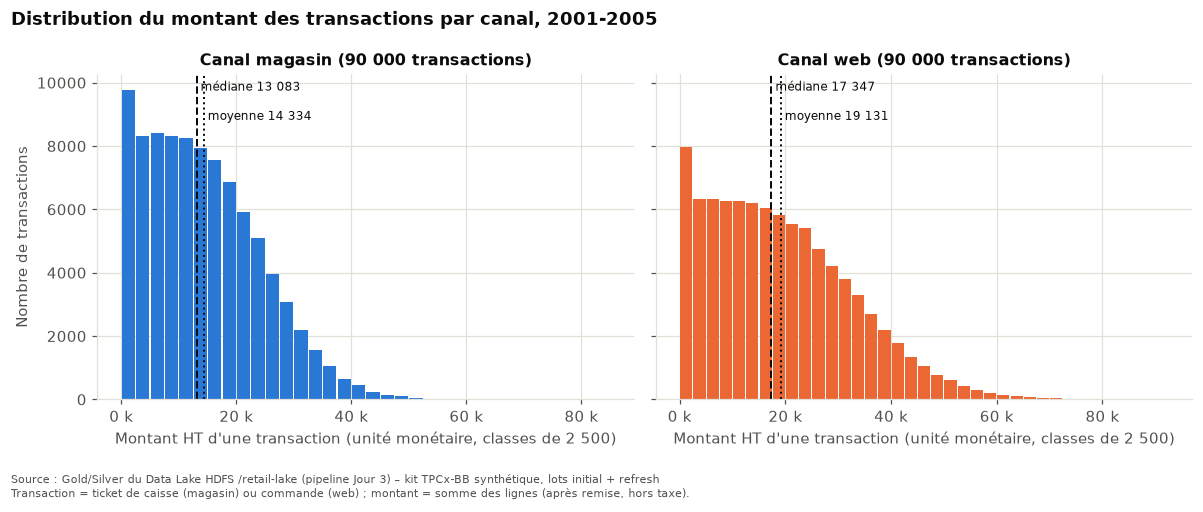

In [14]:
# Distribution du montant des transactions : histogramme calculé DANS Spark (classes de 2 500), seul le
# tableau des classes (quelques dizaines de lignes) est transféré dans Pandas
LARGEUR = 2500
histo = (transactions.withColumn("classe", F.floor(F.col("montant_transaction") / LARGEUR) * LARGEUR)
         .groupBy("canal", "classe").count().toPandas().sort_values(["canal", "classe"]))
histo["classe"] = histo.classe.astype(float)
exporter(histo, "histogramme_montant_transaction")

med = stats[(stats.variable == "montant_transaction")].set_index("canal")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, canal in zip(axes, ["magasin", "web"]):
    h = histo[histo.canal == canal]
    ax.bar(h.classe + LARGEUR / 2, h["count"], width=LARGEUR * 0.92, color=COULEUR_CANAL[canal])
    for nom, val, style in (("médiane", med.loc[canal, "mediane"], "--"), ("moyenne", med.loc[canal, "moyenne"], ":")):
        ax.axvline(val, color=ENCRE, lw=1.3, ls=style)
        ax.text(val, ax.get_ylim()[1] * (0.95 if nom == "médiane" else 0.86), f" {nom} {val:,.0f}".replace(",", " "),
                fontsize=8, color=ENCRE)
    ax.set_title(f"Canal {canal} ({int(h['count'].sum()):,} transactions)".replace(",", " "), fontsize=10.5)
    ax.set_xlabel("Montant HT d'une transaction (unité monétaire, classes de 2 500)")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f} k"))
axes[0].set_ylabel("Nombre de transactions")
fig.suptitle("Distribution du montant des transactions par canal, 2001-2005", fontweight="bold", x=0.01, ha="left")
fig.tight_layout()
finaliser(fig, "distribution_montant_transaction",
          "Transaction = ticket de caisse (magasin) ou commande (web) ; montant = somme des lignes (après remise, hors taxe).")

**Lecture du graphique.** Chaque barre compte les transactions dont le montant HT tombe dans une classe de 2 500.

- **Résultat** : distribution **asymétrique à droite** dans les deux canaux. Magasin : médiane 13 083, moyenne
  14 334 ; web : médiane 17 347, moyenne 19 131. La moyenne est **tirée vers le haut** par quelques grosses
  transactions (jusqu'à 84 763 en magasin et 90 821 sur le web), comme dans l'exemple du cours (moyenne 25, médiane 14).
- **Interprétation** : le « panier moyen » (K03) n'est pas le panier « typique » : une transaction sur deux est
  inférieure à la médiane, environ 9 % plus basse que la moyenne. Une transaction compte de 1 à 14 lignes (7,5 en moyenne).
- **Limites** : montants très élevés et quantités par ligne uniformes de 1 à 100 (moyenne 50,5, médiane 51) : ce
  sont les paramètres du générateur TPCx-BB, pas un comportement d'achat réel. Les transactions à 0 viennent de
  remises de 100 % (Jour 1, contrôle P3).

## 7. Analyse 1 – Évolution du chiffre d'affaires dans le temps et par canal (Q1, Q2)

**Données** : `gold/fait_ventes` (2 canaux, 2001-2005, 60 mois complets). **Méthode** : CA HT par année × mois ×
canal (`groupBy` Spark, 120 lignes), puis **CA moyen par jour** du mois pour comparer des mois de durées différentes
(février a 28 ou 29 jours, janvier 31) ; contrôle : le résultat doit être égal à `gold/ventes_mensuelles_canal`.

In [15]:
mensuel = (fv.groupBy("annee", "mois", "canal")
           .agg(F.sum("montant_ht").alias("ca_ht"), F.countDistinct("document_id").alias("transactions"),
                F.countDistinct("date_vente").alias("jours_avec_ventes"))
           .toPandas().sort_values(["canal", "annee", "mois"]))
mensuel["ca_ht"] = mensuel.ca_ht.astype(float)
mensuel["periode"] = pd.to_datetime(dict(year=mensuel.annee, month=mensuel.mois, day=1))
mensuel["jours_du_mois"] = mensuel.periode.dt.days_in_month
mensuel["ca_par_jour"] = mensuel.ca_ht / mensuel.jours_du_mois

# Contrôle croisé avec l'agrégat Gold du Jour 3
g = df["gold/ventes_mensuelles_canal"].select("annee", "mois", "canal", F.col("ca_ht").cast("double").alias("ca_gold")).toPandas()
chk = mensuel.merge(g, on=["annee", "mois", "canal"])
print("Écart maximal avec gold/ventes_mensuelles_canal :", round((chk.ca_ht - chk.ca_gold).abs().max(), 2),
      "sur", len(chk), "mois x canal")

# Indicateurs de variabilité : coefficient de variation (écart-type / moyenne) du CA mensuel et du CA par jour
variab = mensuel.groupby("canal").agg(ca_mensuel_moyen=("ca_ht", "mean"), cv_ca_mensuel_pct=("ca_ht", lambda s: 100 * s.std() / s.mean()),
                                      cv_ca_par_jour_pct=("ca_par_jour", lambda s: 100 * s.std() / s.mean()),
                                      mois_min=("ca_ht", lambda s: mensuel.loc[s.idxmin(), "periode"].strftime("%Y-%m")),
                                      mois_max=("ca_ht", lambda s: mensuel.loc[s.idxmax(), "periode"].strftime("%Y-%m")))
saison = mensuel.groupby(["canal", "mois"]).ca_par_jour.mean().unstack(0)
saison["ecart_magasin_pct"] = 100 * (saison.magasin / saison.magasin.mean() - 1)
saison["ecart_web_pct"] = 100 * (saison.web / saison.web.mean() - 1)
exporter(mensuel.drop(columns="periode").round(2), "analyse1_ca_mensuel_canal")
exporter(variab.reset_index().round(2), "analyse1_variabilite")
exporter(saison.reset_index().round(2), "analyse1_saisonnalite_ca_par_jour")
display(variab.round(2))
saison.round(1)

Écart maximal avec gold/ventes_mensuelles_canal : 0.0 sur 120 mois x canal
-> Jour4/analytics/outputs/analyse1_ca_mensuel_canal.csv (120 lignes)
-> Jour4/analytics/outputs/analyse1_variabilite.csv (2 lignes)
-> Jour4/analytics/outputs/analyse1_saisonnalite_ca_par_jour.csv (12 lignes)


,ca_mensuel_moyen,cv_ca_mensuel_pct,cv_ca_par_jour_pct,mois_min,mois_max
canal,,,,,
magasin,21501105.7,3.07,1.67,2002-02,2003-10
web,28697110.1,3.28,2.01,2005-02,2001-03


canal,magasin,web,ecart_magasin_pct,ecart_web_pct
mois,,,,
1,698872.7,935293.4,-1.1,-0.8
2,710834.6,943412.9,0.6,0.0
3,705148.2,953405.5,-0.2,1.1
4,703462.7,945348.8,-0.4,0.3
5,702604.4,948266.4,-0.6,0.6
6,705758.9,939701.1,-0.1,-0.3
7,716897.3,944194.7,1.5,0.1
8,705121.4,930277.8,-0.2,-1.3
9,706688.7,951353.4,0.0,0.9


-> Jour4/analytics/visualizations/evolution_ventes_mensuelles.png


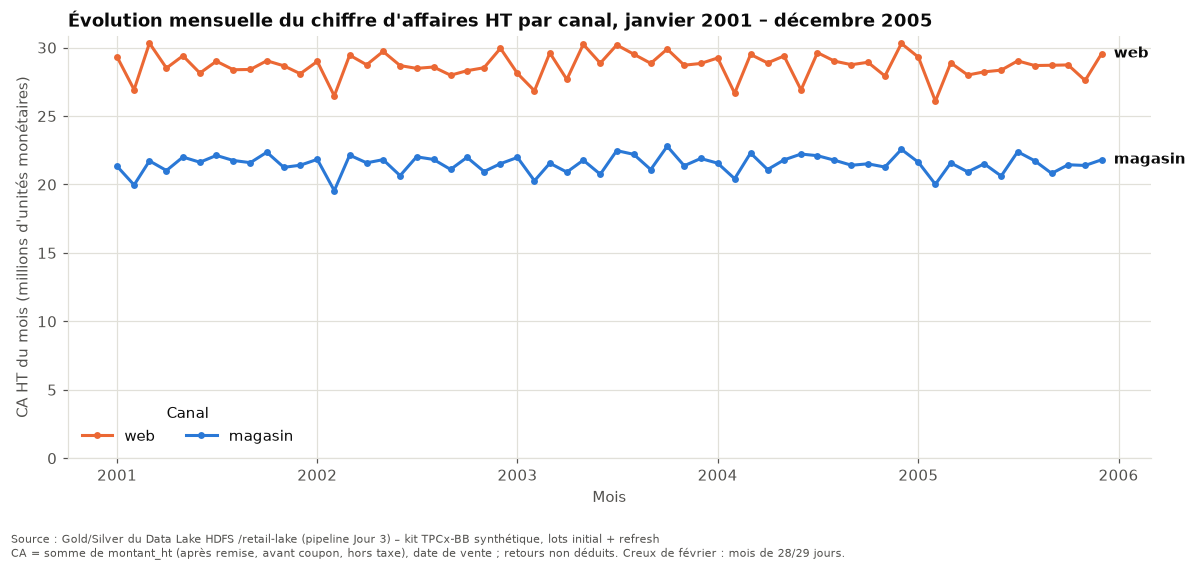

In [16]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for canal in ["web", "magasin"]:
    m = mensuel[mensuel.canal == canal]
    ax.plot(m.periode, m.ca_ht / 1e6, color=COULEUR_CANAL[canal], lw=2, marker="o", ms=3.5, label=canal)
    ax.annotate(canal, (m.periode.iloc[-1], m.ca_ht.iloc[-1] / 1e6), xytext=(8, 0), textcoords="offset points",
                color=ENCRE, fontsize=9.5, va="center", fontweight="bold")
ax.set_ylim(0, None)
ax.set_title("Évolution mensuelle du chiffre d'affaires HT par canal, janvier 2001 – décembre 2005", loc="left")
ax.set_xlabel("Mois")
ax.set_ylabel("CA HT du mois (millions d'unités monétaires)")
ax.legend(title="Canal", loc="lower left", frameon=False, ncol=2)
fig.tight_layout()
finaliser(fig, "evolution_ventes_mensuelles",
          "CA = somme de montant_ht (après remise, avant coupon, hors taxe), date de vente ; retours non déduits. "
          "Creux de février : mois de 28/29 jours.")

**Lecture du graphique.** Une courbe par canal, un point par mois (60 mois), axe vertical démarrant à 0.

- **Résultat** : CA mensuel moyen de **21,5 M** en magasin et **28,7 M** sur le web. Les courbes sont presque plates :
  coefficient de variation de **3,1 %** (magasin) et **3,3 %** (web). Les creux réguliers sont les mois de **février**
  (mois le plus bas : février 2002 en magasin, février 2005 sur le web).
- **Comparer des périodes de même durée** : rapporté au nombre de jours du mois, le coefficient de variation tombe à
  **1,7 %** et **2,0 %** : environ la moitié des variations visibles vient seulement de la longueur des mois. Par mois
  calendaire, le CA par jour s'écarte de la moyenne de −1,1 % à +1,5 % (magasin) : **aucune saisonnalité** (pas de pic
  en fin d'année).
- **Évolution annuelle (K06)** : entre −1,61 % et +1,01 % par an ; 2005 est en baisse dans les deux canaux (−1,61 %
  magasin, −1,15 % web). La part du web (K07) reste entre 57,0 % et 57,3 % chaque année.
- **Limites** : données synthétiques sans saisonnalité, ni promotion datée, ni événement : on ne peut pas expliquer
  la baisse 2005, qui reste du même ordre que les variations des autres années. CA à la date de vente, retours non déduits.

## 8. Analyse 2 – Différences entre les magasins (Q6)

**Données** : `gold/fait_ventes` (canal magasin) joint à `silver/store` (nom, ville, surface, effectif) sur
`store_sk` = `s_store_sk` (12 magasins, aucune ligne de vente sans magasin). **Méthode** : CA HT, tickets, panier
moyen et quantités par magasin sur 2001-2005 ; écart à la moyenne des magasins ; CA rapporté à la surface et à
l'effectif pour illustrer qu'un CA plus élevé ne signifie pas un magasin « plus performant ». Contrôle :
égalité avec `gold/ventes_magasin_annee`.

In [17]:
store = df["silver/store"].select(F.col("s_store_sk").alias("store_sk"), "s_store_name", "s_city", "s_state",
                                  "s_floor_space", "s_number_employees")
mag = (fv.filter("canal = 'magasin'").groupBy("store_sk")
       .agg(F.sum("montant_ht").alias("ca_ht"), F.countDistinct("document_id").alias("tickets"),
            F.sum("quantite").alias("quantite"), F.count("*").alias("lignes"))
       .join(store, "store_sk", "left").toPandas().sort_values("ca_ht", ascending=False))
mag["ca_ht"] = mag.ca_ht.astype(float)
mag["panier_moyen"] = mag.ca_ht / mag.tickets
mag["ecart_moyenne_pct"] = 100 * (mag.ca_ht / mag.ca_ht.mean() - 1)
mag["part_ca_magasins_pct"] = 100 * mag.ca_ht / mag.ca_ht.sum()
mag["ca_par_1000_unites_surface"] = 1000 * mag.ca_ht / mag.s_floor_space
mag["ca_par_employe"] = mag.ca_ht / mag.s_number_employees
mag["rang_ca"] = range(1, len(mag) + 1)
mag["rang_ca_surface"] = mag.ca_par_1000_unites_surface.rank(ascending=False).astype(int)

gm = df["gold/ventes_magasin_annee"].groupBy("s_store_sk").agg(F.sum("ca_ht").cast("double").alias("ca_gold")).toPandas()
chk = mag.merge(gm, left_on="store_sk", right_on="s_store_sk")
print("Écart maximal avec gold/ventes_magasin_annee :", round((chk.ca_ht - chk.ca_gold).abs().max(), 2))
print(f"Écart entre le 1er et le dernier magasin : {100 * (mag.ca_ht.max() / mag.ca_ht.min() - 1):.2f} % ; "
      f"coefficient de variation du CA : {100 * mag.ca_ht.std() / mag.ca_ht.mean():.2f} %")
exporter(mag.round(2), "analyse2_magasins")
mag[["rang_ca", "s_store_name", "s_city", "s_state", "ca_ht", "tickets", "panier_moyen", "ecart_moyenne_pct",
     "ca_par_1000_unites_surface", "rang_ca_surface", "ca_par_employe"]].round(2)

Écart maximal avec gold/ventes_magasin_annee : 0.0
Écart entre le 1er et le dernier magasin : 5.15 % ; coefficient de variation du CA : 1.40 %
-> Jour4/analytics/outputs/analyse2_magasins.csv (12 lignes)


,rang_ca,s_store_name,s_city,s_state,ca_ht,tickets,panier_moyen,ecart_moyenne_pct,ca_par_1000_unites_surface,rang_ca_surface,ca_par_employe
6,1,Buffalo,Lewisburg,KS,1.108085e+08,7717,14359.02,3.07,12938.87,8,492482.32
11,2,Forest,Post Oak,CO,1.084949e+08,7536,14396.88,0.92,12202.08,11,499976.50
3,3,Elmwood,Lakeside,KY,1.084934e+08,7547,14375.70,0.92,14449.36,7,427139.31
0,4,Germantown,Pierce,WV,1.084217e+08,7511,14435.06,0.85,17240.13,3,509022.14
8,5,Williamstown,State Line,TX,1.080574e+08,7480,14446.18,0.51,12180.49,12,362608.86
2,6,Pioneer,Austin,TX,1.076360e+08,7473,14403.32,0.12,18631.74,1,487040.86
9,7,Hillside,Jerusalem,TN,1.074735e+08,7497,14335.54,-0.03,12280.81,10,440465.29
1,8,Bedford,Lyons,KY,1.068827e+08,7515,14222.58,-0.58,15182.81,6,483632.20
4,9,Bloomfield,Union Hill,IN,1.065499e+08,7357,14482.79,-0.89,12659.26,9,473555.18
7,10,Egypt,Redland,KY,1.059735e+08,7454,14217.00,-1.43,15264.57,5,492899.95


-> Jour4/analytics/visualizations/ventes_par_magasin.png


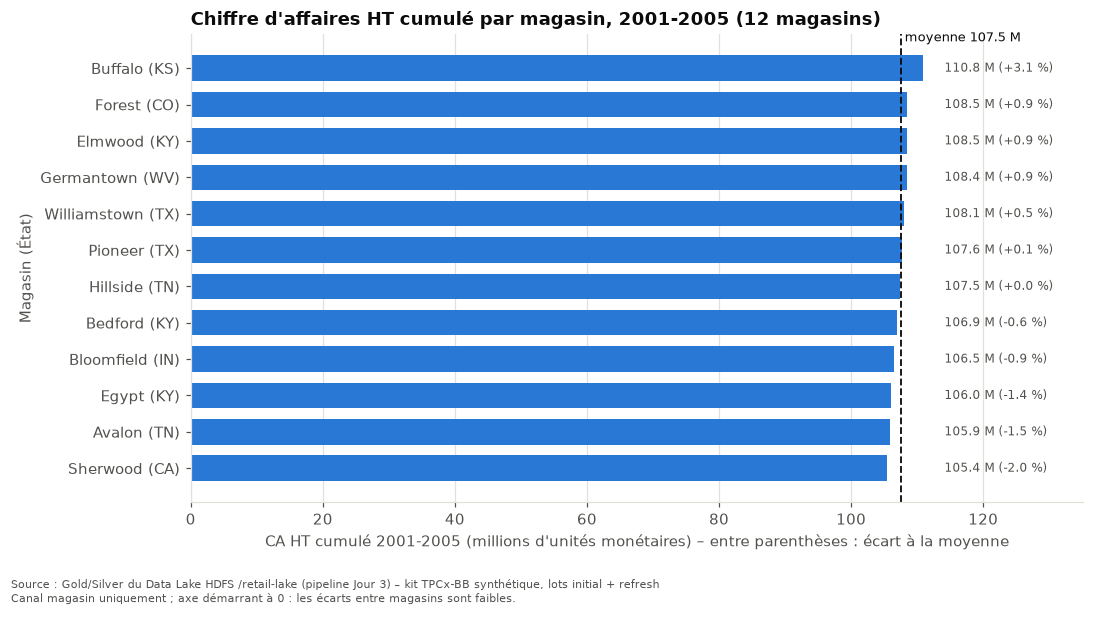

In [18]:
m = mag.sort_values("ca_ht")
fig, ax = plt.subplots(figsize=(10, 5.2))
ax.barh(m.s_store_name + " (" + m.s_state + ")", m.ca_ht / 1e6, color=COULEUR_CANAL["magasin"], height=0.7)
moy = m.ca_ht.mean() / 1e6
ax.axvline(moy, color=ENCRE, lw=1.2, ls="--")
ax.text(moy, len(m) - 0.35, f" moyenne {moy:.1f} M", fontsize=8.5, color=ENCRE, va="bottom")
x_lab = m.ca_ht.max() / 1e6 * 1.03          # étiquettes alignées à droite des barres, hors de la ligne de moyenne
for y, (v, e) in enumerate(zip(m.ca_ht / 1e6, m.ecart_moyenne_pct)):
    e = 0.0 if abs(e) < 0.05 else e
    ax.text(x_lab, y, f"{v:.1f} M ({e:+.1f} %)", va="center", fontsize=8, color=ENCRE2)
ax.set_xlim(0, m.ca_ht.max() / 1e6 * 1.22)
ax.grid(axis="y", visible=False)
ax.set_title("Chiffre d'affaires HT cumulé par magasin, 2001-2005 (12 magasins)", loc="left")
ax.set_xlabel("CA HT cumulé 2001-2005 (millions d'unités monétaires) – entre parenthèses : écart à la moyenne")
ax.set_ylabel("Magasin (État)")
fig.tight_layout()
finaliser(fig, "ventes_par_magasin", "Canal magasin uniquement ; axe démarrant à 0 : les écarts entre magasins sont faibles.")

**Lecture du graphique.** Barres horizontales triées, axe démarrant à 0, ligne pointillée = moyenne des 12 magasins.

- **Résultat** : CA cumulé de **105,4 M** (Sherwood, CA) à **110,8 M** (Buffalo, KS), soit **5,15 %** d'écart entre le
  premier et le dernier ; coefficient de variation **1,4 %**. Seul Buffalo se détache (+3,1 % au-dessus de la moyenne).
- **D'où vient l'écart ?** Le nombre de tickets varie de 7 357 à 7 717 (+4,9 %) alors que le panier moyen ne varie
  que de 14 125 à 14 483 (+2,5 %) : les différences viennent surtout du **nombre de transactions**.
- **Le classement dépend de l'indicateur** : rapporté à la surface (`s_floor_space`), Pioneer (6e en CA) passe 1er et
  Williamstown (5e en CA, effectif le plus élevé : 298 employés) passe dernier. Un CA plus élevé ne prouve donc pas
  qu'un magasin est « plus performant ».
- **Limites** : surfaces et effectifs synthétiques (unité non documentée), pas de fréquentation, de date d'ouverture
  ni de zone de chalandise : ces ratios illustrent la démarche, ils ne permettent pas de juger un magasin.

## 9. Analyse 3 – Catégories qui génèrent le plus de chiffre d'affaires (Q3)

**Données** : `gold/fait_ventes` (catégorie issue de `silver/item`, 9 catégories, aucune non renseignée).
**Méthode** : CA HT par catégorie et canal sur 2001-2005, part dans le CA total et part cumulée.

In [19]:
cat = (fv.groupBy("categorie", "canal").agg(F.sum("montant_ht").alias("ca_ht")).toPandas()
       .pivot(index="categorie", columns="canal", values="ca_ht").astype(float))
cat["total"] = cat.magasin + cat.web
cat = cat.sort_values("total", ascending=False)
cat["part_pct"] = 100 * cat.total / cat.total.sum()
cat["part_cumulee_pct"] = cat.part_pct.cumsum()
cat["part_web_pct"] = 100 * cat.web / cat.total
exporter(cat.reset_index().round(2), "analyse3_categories")
cat.round(2)

-> Jour4/analytics/outputs/analyse3_categories.csv (9 lignes)


canal,magasin,web,total,part_pct,part_cumulee_pct,part_web_pct
categorie,,,,,,
Music,5.831864e+08,7.734581e+08,1.356644e+09,45.04,45.04,57.01
Books,3.443484e+08,4.592895e+08,8.036379e+08,26.68,71.73,57.15
Movies & TV,8.381585e+07,1.130035e+08,1.968193e+08,6.53,78.26,57.41
Electronics,6.224277e+07,8.560690e+07,1.478497e+08,4.91,83.17,57.90
Clothing & Accessories,6.329626e+07,8.333154e+07,1.466278e+08,4.87,88.04,56.83
Home & Kitchen,4.641235e+07,6.393615e+07,1.103485e+08,3.66,91.70,57.94
Sports & Outdoors,4.587255e+07,6.089522e+07,1.067678e+08,3.54,95.25,57.04
Toys & Games,3.079282e+07,4.211550e+07,7.290832e+07,2.42,97.67,57.77
Tools & Home Improvement,3.009895e+07,4.019023e+07,7.028918e+07,2.33,100.00,57.18


-> Jour4/analytics/visualizations/ventes_par_categorie.png


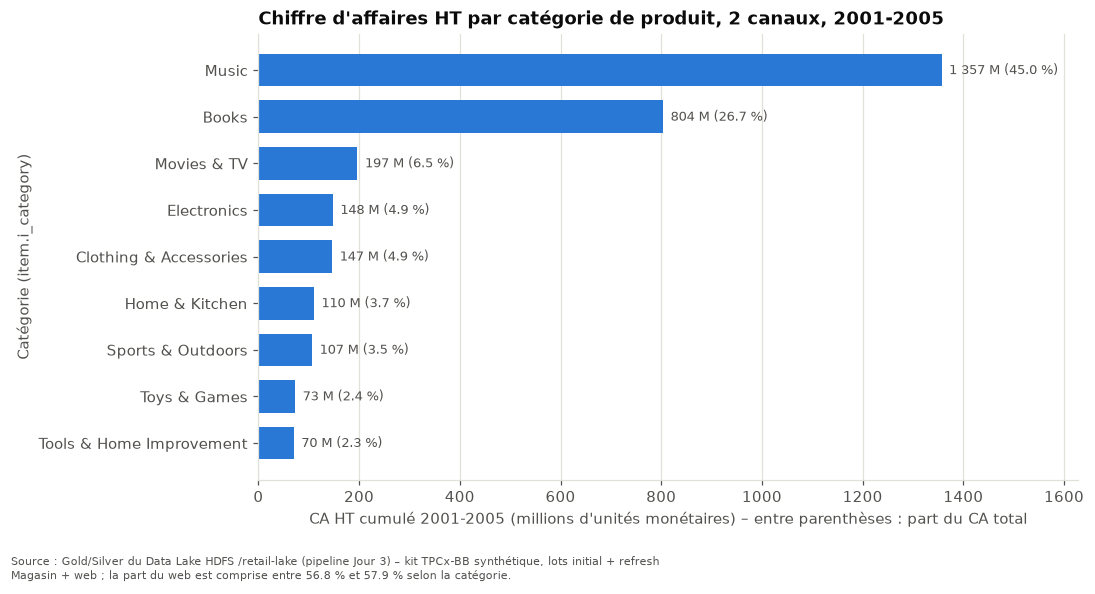

In [20]:
c = cat.sort_values("total")
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(c.index, c.total / 1e6, color=COULEUR_CANAL["magasin"], height=0.7)
for y, (v, p) in enumerate(zip(c.total / 1e6, c.part_pct)):
    ax.text(v + 15, y, f"{v:,.0f} M ({p:.1f} %)".replace(",", " "), va="center", fontsize=8.5, color=ENCRE2)
ax.set_xlim(0, c.total.max() / 1e6 * 1.2)
ax.grid(axis="y", visible=False)
ax.set_title("Chiffre d'affaires HT par catégorie de produit, 2 canaux, 2001-2005", loc="left")
ax.set_xlabel("CA HT cumulé 2001-2005 (millions d'unités monétaires) – entre parenthèses : part du CA total")
ax.set_ylabel("Catégorie (item.i_category)")
fig.tight_layout()
finaliser(fig, "ventes_par_categorie", "Magasin + web ; la part du web est comprise entre "
          f"{cat.part_web_pct.min():.1f} % et {cat.part_web_pct.max():.1f} % selon la catégorie.")

**Lecture du graphique.** CA cumulé 2001-2005 des deux canaux, une barre par catégorie, triées.

- **Résultat** : forte concentration : **Music (45,0 %)** et **Books (26,7 %)** font **71,7 %** du CA ; les 7 autres
  catégories pèsent chacune entre 2,3 % et 6,5 %. La part du web est la même partout (56,8 % à 57,9 %).
- **Interprétation prudente** : Music représente aussi **45 % des lignes** et **45 % des produits vendus** (8 171 produits
  sur les 17 886 produits vendus). La concentration reflète donc la **taille de l'assortiment**, pas une meilleure performance :
  le CA **par produit** de Music (166 k) est même inférieur à celui de Clothing & Accessories (240 k) ou Home & Kitchen (231 k).
- **Limites** : catégories du référentiel `item` (version courante), unités de vente hétérogènes (`i_units`) : les
  quantités ne s'additionnent pas entre catégories sans précaution ; marge non interprétable, donc pas d'analyse de rentabilité.

## 10. Analyse 4 – Taux de retour par catégorie (Q8)

**Données** : `gold/retours_categorie` (Jour 3). **Définition (K09)** : numérateur = quantités retournées
rattachées à une vente (canal, document, article) ; dénominateur = quantités vendues ; **même cohorte** = année de
la **vente** et même catégorie ; période 2001-2005. Les 407 retours magasin et 371 retours web du lot refresh sans vente
retrouvée (anomalie Q24 du Jour 3) ne peuvent pas être rattachés à une catégorie vendue : ils sont exclus du taux.

In [21]:
rc = (df["gold/retours_categorie"].groupBy("categorie", "canal")
      .agg(F.sum("quantite_retournee").alias("q_ret"), F.sum("quantite_vendue").alias("q_vend"),
           F.sum("montant_retours").alias("montant_retours"), F.sum("ca_ht").alias("ca_ht"))
      .toPandas())
rc["taux_retour_pct"] = 100 * rc.q_ret / rc.q_vend
rc["taux_retour_montant_pct"] = 100 * rc.montant_retours.astype(float) / rc.ca_ht.astype(float)
tr = rc.pivot(index="categorie", columns="canal", values="taux_retour_pct").sort_values("magasin")
exporter(rc.round(3), "analyse4_retours_categorie")
moy = {c: 100 * rc[rc.canal == c].q_ret.sum() / rc[rc.canal == c].q_vend.sum() for c in ["magasin", "web"]}
print("Taux de retour global (quantité) :", {k: round(v, 2) for k, v in moy.items()})
tr.round(2)

-> Jour4/analytics/outputs/analyse4_retours_categorie.csv (18 lignes)
Taux de retour global (quantité) : {'magasin': np.float64(2.85), 'web': np.float64(2.91)}


canal,magasin,web
categorie,,
Electronics,2.66,2.88
Movies & TV,2.72,2.77
Tools & Home Improvement,2.78,3.12
Clothing & Accessories,2.83,2.86
Music,2.83,2.91
Home & Kitchen,2.87,2.91
Toys & Games,2.88,3.24
Books,2.95,2.93
Sports & Outdoors,2.95,2.94


-> Jour4/analytics/visualizations/taux_retour_categorie.png


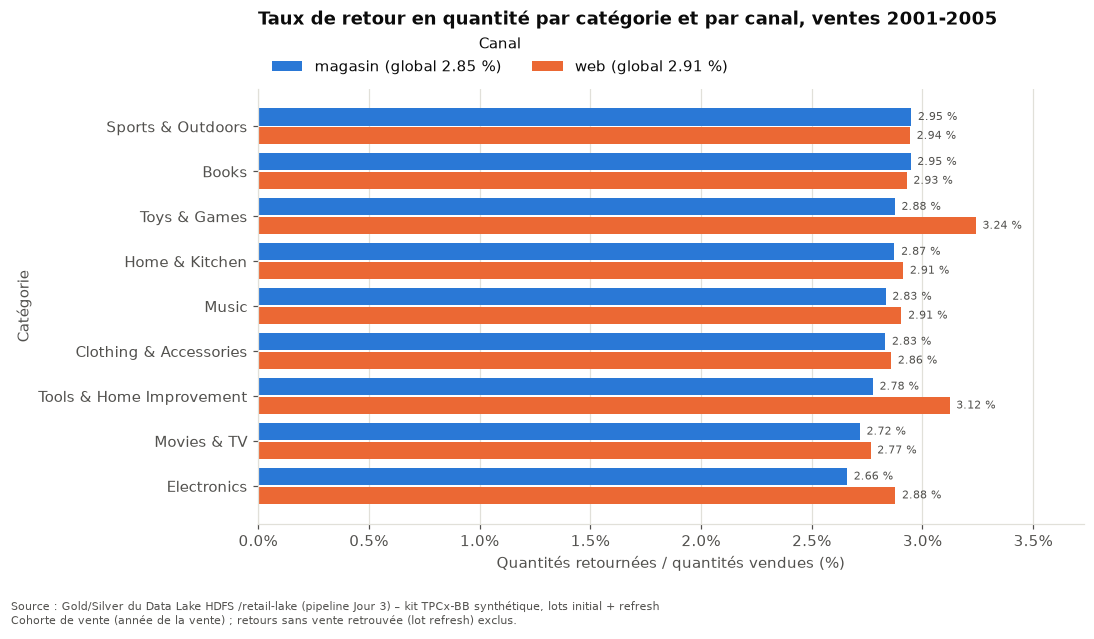

In [22]:
import numpy as np
fig, ax = plt.subplots(figsize=(10, 5.4))
y = np.arange(len(tr))
h = 0.38
for i, canal in enumerate(["magasin", "web"]):
    ax.barh(y + (h / 2 + 0.02) * (1 if canal == "magasin" else -1), tr[canal], height=h,
            color=COULEUR_CANAL[canal], label=f"{canal} (global {moy[canal]:.2f} %)")
    for yy, v in zip(y + (h / 2 + 0.02) * (1 if canal == "magasin" else -1), tr[canal]):
        ax.text(v + 0.03, yy, f"{v:.2f} %", va="center", fontsize=7.5, color=ENCRE2)
ax.set_yticks(y, tr.index)
ax.set_xlim(0, tr.values.max() * 1.15)
ax.xaxis.set_major_locator(mtick.MultipleLocator(0.5))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
ax.grid(axis="y", visible=False)
ax.legend(title="Canal", loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False)
ax.set_title("Taux de retour en quantité par catégorie et par canal, ventes 2001-2005", loc="left", pad=42)
ax.set_xlabel("Quantités retournées / quantités vendues (%)")
ax.set_ylabel("Catégorie")
fig.tight_layout()
finaliser(fig, "taux_retour_categorie", "Cohorte de vente (année de la vente) ; retours sans vente retrouvée (lot refresh) exclus.")

**Lecture du graphique.** Pour chaque catégorie, une barre par canal ; entre parenthèses dans la légende : taux global.

- **Résultat** : taux de retour global de **2,85 %** (magasin) et **2,91 %** (web). En magasin, toutes les catégories
  sont entre 2,66 % (Electronics) et 2,95 % (Sports & Outdoors, Books). Sur le web, deux catégories se détachent :
  **Toys & Games (3,24 %)** et **Tools & Home Improvement (3,12 %)**, soit environ 0,35 point de plus qu'en magasin.
- **Interprétation** : les écarts sont faibles (moins de 0,6 point) ; ceux du web sur Toys et Tools portent sur de
  petits volumes (27 035 et 24 929 unités retournées en 5 ans) et peuvent relever du hasard du générateur.
- **Limites** : taux calculé sur la **cohorte de vente** (retours rattachés aux ventes de 2001-2005) ; les retours
  du lot refresh sans vente retrouvée (407 magasin, 371 web) sont exclus ; motifs de retour synthétiques (texte
  aléatoire), donc pas d'analyse des causes.

## 11. Constats, limites et recommandations (livrable J4-06)

| # | Résultat observé | Interprétation possible | Limite | Recommandation |
|---|---|---|---|---|
| C1 | CA très stable : coefficient de variation mensuel de 3 %, réduit à 2 % à nombre de jours égal ; aucun mois calendaire ne s'écarte de plus de 1,5 % ; 2005 en baisse de 1,6 % (magasin). | Pas de saisonnalité ni de tendance : la baisse 2005 est du même ordre que les variations des autres années. | Données synthétiques ; ni promotions datées, ni météo, ni événements. | Ne pas fixer d'objectifs saisonniers sur ces données ; suivre K06 en CA **par jour** pour comparer des mois de durées différentes. |
| C2 | 12 magasins entre 105,4 et 110,8 M (écart 5 %), écarts dus surtout au nombre de tickets ; le classement change complètement si l'on rapporte le CA à la surface. | Aucun magasin réellement « en retrait » sur le CA ; Buffalo se détache légèrement. | Surface et effectif synthétiques ; pas de fréquentation. | Piloter les magasins avec plusieurs KPI (CA, tickets, panier, CA par surface) et ajouter la fréquentation avant toute décision. |
| C3 | Music + Books = 71,7 % du CA, mais aussi 71,7 % des lignes et 76 % des produits vendus. | La concentration vient de la profondeur de l'assortiment ; le CA par produit est plus élevé dans les petites catégories. | Pas de marge interprétable, pas de coût de stockage. | Analyser l'assortiment au niveau produit (CA par produit, rotation) plutôt que par catégorie avant de réduire ou d'étendre une gamme. |
| C4 | Taux de retour de 2,85 % (magasin) et 2,91 % (web), homogène ; Toys & Games et Tools sur le web à plus de 3,1 %. | Écarts faibles ; légère sur-représentation des retours web sur deux catégories. | Petits volumes, motifs synthétiques, retours orphelins du lot refresh exclus. | Mettre ces deux catégories sous surveillance (suivi trimestriel) plutôt que d'agir immédiatement. |
| C5 | Panier moyen magasin 14 334 contre une médiane de 13 083 ; web 19 131 contre 17 347. | La moyenne surestime la transaction « typique ». | Montants irréalistes (générateur). | Publier le panier moyen **avec** la médiane et la distribution. |

**Indicateurs non calculés ou non interprétables** : marge (K11) et taux de remise (K05) (paramètres du générateur) ;
vrai taux de conversion web (pas d'identifiant de session) ; stock par magasin (le stock est relevé par entrepôt) ;
effet causal d'une promotion (une association n'est pas une preuve).

**Rappel** : une corrélation ne démontre pas une causalité, et ces données TPCx-BB sont **synthétiques** : les
constats valident une démarche, pas une stratégie commerciale.

## 12. Synthèse des résultats exportés

Les tableaux ci-dessous sont repris dans les livrables PDF (J4-01 à J4-06). Tous les fichiers sont régénérés à
chaque exécution du notebook.

In [23]:
fichiers = sorted([p for p in OUT.glob("*.csv")] + [p for p in VIZ.glob("*.png")])
pd.DataFrame([(p.parent.name, p.name, p.stat().st_size) for p in fichiers], columns=["dossier", "fichier", "octets"])

,dossier,fichier,octets
0,outputs,analyse1_ca_mensuel_canal.csv,5612
1,outputs,analyse1_saisonnalite_ca_par_jour.csv,445
2,outputs,analyse1_variabilite.csv,167
3,outputs,analyse2_magasins.csv,1539
4,outputs,analyse3_categories.csv,686
5,outputs,analyse4_retours_categorie.csv,1350
6,outputs,controle_kpi_jour1.csv,2620
7,outputs,controles_prealables.csv,1030
8,outputs,environnement.csv,408
9,outputs,histogramme_montant_transaction.csv,1134


In [24]:
spark.stop()